# Evaluating a RAG system with HotpotQA

Imagine asking, “In which city was the creator of Lantern Atlas born?” One document identifies the creator; another gives the birthplace. An assistant can fail by finding only one document, misreading both, or answering correctly but citing unrelated sentences. This tutorial makes those failures visible.

**You will learn to:** read HotpotQA's raw JSON; preserve sentence addresses during retrieval; build and inspect a bounded workflow; calculate official answer, supporting-fact and joint scores; compare retrieval settings; and export a reproducible live-model experiment.

**Prerequisites:** basic Python lists, dictionaries and functions. Allow 60–90 minutes. The core lesson runs without credentials after package installation. A later, explicitly enabled section calls a hosted model and can incur charges. No live-model scores are bundled or implied.

Companion [slides](slides/index.html) • [setup guide](README.md) • [data provenance](data/README.md) • [primary sources](SOURCES.md)

## 1. Start the environment

From the repository root, run these commands in a terminal:

```bash
uv sync --locked
uv run jupyter lab hotpotqa_rag_evaluation.ipynb
```

`uv` creates a separate Python environment using `pyproject.toml` and the recorded versions in `uv.lock`. Select its Python kernel. Run cells from top to bottom with **Shift+Enter**. If variables become confusing, use **Restart Kernel and Run All**. Keep this notebook with its helper files and data directory.

The setup below finds this module from either its own directory or the repository root. It never installs packages or calls an API inside the notebook.

In [1]:
from pathlib import Path
import sys, os, json, inspect, hashlib
import pandas as pd
from IPython.display import display, SVG, Code

ROOT = Path.cwd()
assert (ROOT / "rag.py").exists(), "Start Jupyter from the module directory or repository root."
sys.path.insert(0, str(ROOT))
from rag import make_index, build_graph, ScriptedBackend, LiveBackend, Answer, Citation
from metrics import answer_metrics, supporting_fact_metrics, score_example, evaluate
from evaluation import retrieval_metrics, run_experiment, save_experiment

RUN_LIVE = False
LIVE_N = 2
K = 2
MAX_ROUNDS = 2
print("Module:", ROOT.name, "| Live model enabled:", RUN_LIVE)

Module: hotpotqa | Live model enabled: False


## 2. What are RAG and HotpotQA?

**Retrieval-augmented generation (RAG)** first finds text relevant to a question, then gives that text to a language model to produce an answer. A retriever chooses the material; a reader or generator uses it. An **agentic** workflow can choose another search when the evidence seems insufficient.

### The RAG StateGraph at a glance

![RAG StateGraph: START → retrieve → grade; grade generates when evidence is sufficient or the round limit is reached, otherwise rewrites the query and retrieves again. Errors in retrieve, grade or rewrite route to END; generate always routes to END.](assets/stategraph.svg)

Read the solid arrows as the normal workflow and the dashed red arrows as error exits. Both **END** boxes represent the same terminal state. `retrieve` searches the current query and accumulates evidence; `grade`, `rewrite`, and `generate` call the backend (a model in live mode). Every node is wrapped by `record_node` to capture timing, trace events, and errors.

The shared `RAGState` carries `question`, `query`, `documents`, `rounds`, `sufficient`, `answer`, `backend_calls`, `trace`, and `error`. A rewrite changes the search query, not the original question. With `MAX_ROUNDS = 2`, retrieval runs at most twice. Reaching the cap routes to generation even if evidence is insufficient; the generator may abstain. Section 8 builds this graph in code.

### HotpotQA: evaluating answers and evidence

**HotpotQA** is a question-answering dataset introduced by Yang and colleagues in 2018. It contains about 113,000 Wikipedia-based questions across its splits. Many require connecting information across documents. In labeled data, a question comes with a reference answer and **supporting facts**: human-annotated sentence addresses that support that answer. This lets us evaluate evidence selection as well as answer text. [Paper](https://aclanthology.org/D18-1259/)

A **bridge** question uses an intermediate entity: book → creator → birthplace. A **comparison** question asks about two entities, such as which person was born earlier. Not every question requires a literal two-step search, and two supporting documents can contain more than two annotated sentences.

HotpotQA is a historical benchmark. Its labels describe its source material, not necessarily today's world. It does not establish that a model has avoided memorization, or that its explanation reveals its internal reasoning.

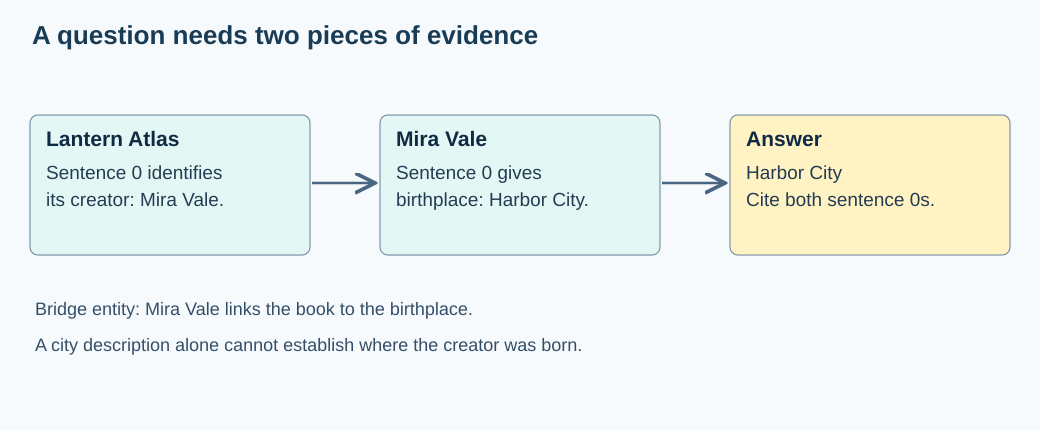

In [2]:
display(SVG(filename=str(ROOT / "assets" / "bridge.svg")))

## 3. Choose the evaluation setting before writing code

| Setting | What the system searches | What a score measures |
|---|---|---|
| Distractor | Ten candidate paragraphs for each question, including the two source paragraphs and distractors | Evidence selection and answering inside a supplied candidate set |
| Fullwiki | The benchmark's processed Wikipedia corpus | Corpus retrieval as well as answering and evidence selection |
| This teaching lab | Each bundled real record's distractor paragraphs | A small diagnostic exercise, **not** an official benchmark result |

Pooling the paragraphs from a few development examples does not create the official fullwiki corpus. Loading a file named `fullwiki` also does not automatically build the corpus index. A real fullwiki experiment needs the released processed corpus, its paragraph/sentence identity mapping, and a documented retrieval protocol.

Use training data for development and a held-out development subset for a final local comparison. The official test answers are hidden. The bundled records are deliberately small and inspectable; once you study their labels, treat them as development material. [Settings and downloads](https://hotpotqa.github.io/)

## 4. Read a complete, tiny raw JSON example

First use a **synthetic teaching story**, not a benchmark record. Every name and fact below is invented. It follows the HotpotQA field layout, but has four paragraphs instead of ten and uses `level: "toy"` to prevent confusion with official difficulty labels.

JSON objects use named fields, arrays use square brackets, and strings use quotation marks. The raw file is [data/toy_example.json](data/toy_example.json). We read it with the standard library, without a dataset wrapper.

In [3]:
toy_path = ROOT / "data" / "toy_example.json"
toy = json.loads(toy_path.read_text())
print(json.dumps(toy, indent=2, ensure_ascii=False))

{
  "_id": "synthetic-lantern-atlas-001",
  "question": "In which city was the creator of Lantern Atlas born?",
  "answer": "Harbor City",
  "type": "bridge",
  "level": "toy",
  "supporting_facts": [
    [
      "Lantern Atlas",
      0
    ],
    [
      "Mira Vale",
      0
    ]
  ],
  "context": [
    [
      "Lantern Atlas",
      [
        "Lantern Atlas is an invented book whose creator is Mira Vale."
      ]
    ],
    [
      "Mira Vale",
      [
        "Mira Vale was born in Harbor City."
      ]
    ],
    [
      "Harbor City",
      [
        "Harbor City is an invented coastal city."
      ]
    ],
    [
      "Cloud Almanac",
      [
        "Cloud Almanac is an invented book created by Niko Fern."
      ]
    ]
  ]
}


Read the fields as follows:

| Field | Meaning | Who may use it during evaluation? |
|---|---|---|
| `_id` | Stable question identifier; prediction files use it as a key | Harness |
| `question` | What the system must answer | Agent |
| `context` | Pairs of document title and a list of original sentences | Retriever/agent |
| `answer` | Reference answer string | Scorer after inference |
| `supporting_facts` | Pairs `[title, sentence_index]` | Scorer after inference |
| `type` | Bridge or comparison metadata | Analysis after inference |
| `level` | Dataset difficulty metadata; `toy` here is tutorial-only | Analysis |

`["Mira Vale", 0]` means **the first sentence in the paragraph titled Mira Vale**. The index is zero-based. It is not a paragraph number, character offset, or an embedding ID. A title must match exactly for supporting-fact scoring. Whitespace already present in the original sentences should be preserved.

The next helper turns the supporting-fact references into readable evidence. Its three body lines work together:

1. `paragraphs = dict(record["context"])` turns the list of `[title, sentences]` pairs into a dictionary. You can now look up a paragraph by its title: `paragraphs["Mira Vale"]` gives its list of sentences.
2. `return [{"title": title, "sentence_index": i, "sentence": paragraphs[title][i]}` describes each output row. `paragraphs[title]` selects the named paragraph, then `[i]` selects one sentence from it. With `title = "Mira Vale"` and `i = 0`, the sentence is `"Mira Vale was born in Harbor City."`.
3. `for title, i in record["supporting_facts"]]` repeats that lookup for each annotated `[title, sentence_index]` pair. Python puts the two values into `title` and `i`. This line completes the list comprehension started on the previous line; together they build and return a list of evidence rows.

`display(pd.DataFrame(supporting_text(toy)))` calls the helper on the toy record and displays those rows as a table. It shows two evidence sentences: Lantern Atlas was created by Mira Vale, and Mira Vale was born in Harbor City. This helper reads the supplied evidence labels; it does not search for or predict evidence.

In [4]:
print(json.dumps(toy["context"], indent=2, ensure_ascii=False, sort_keys=True))

[
  [
    "Lantern Atlas",
    [
      "Lantern Atlas is an invented book whose creator is Mira Vale."
    ]
  ],
  [
    "Mira Vale",
    [
      "Mira Vale was born in Harbor City."
    ]
  ],
  [
    "Harbor City",
    [
      "Harbor City is an invented coastal city."
    ]
  ],
  [
    "Cloud Almanac",
    [
      "Cloud Almanac is an invented book created by Niko Fern."
    ]
  ]
]


In [5]:
def supporting_text(record):
    paragraphs = dict(record["context"])
    return [{"title": title, "sentence_index": i, "sentence": paragraphs[title][i]}
            for title, i in record["supporting_facts"]]

display(pd.DataFrame(supporting_text(toy)))
print("Question:", toy["question"])
print("Reference answer:", toy["answer"])

,title,sentence_index,sentence
0,Lantern Atlas,0,Lantern Atlas is an invented book whose creato...
1,Mira Vale,0,Mira Vale was born in Harbor City.


Question: In which city was the creator of Lantern Atlas born?
Reference answer: Harbor City


**Check your understanding.** Why is the Harbor City paragraph insufficient by itself? It describes the city, but does not establish that the creator of Lantern Atlas was born there. We need both links in the chain. The gold labels above are visible for teaching; later we keep them outside the agent's inputs.

## 5. Inspect a real HotpotQA record

Now switch to a small attributed extract from the actual distractor development set. The data README records the source, selection procedure, licenses and checksums. These records retain all candidate paragraphs and supporting-fact indices. This sample is for learning, not an estimate of population accuracy.

In [6]:
records = json.loads((ROOT / "data" / "dev_sample.json").read_text())
real = json.loads((ROOT / "data" / "example.json").read_text())
print("Bundled real questions:", len(records))
print("ID:", real["_id"], "| type:", real["type"], "| level:", real["level"])
print("Question:", real["question"])
print("Candidate paragraphs:", len(real["context"]))
print("Raw JSON file:", "data/example.json")
print(json.dumps({k: v for k, v in real.items() if k != "context"}, indent=2))
display(pd.DataFrame(supporting_text(real)))

Bundled real questions: 10
ID: 5abd94525542992ac4f382d2 | type: bridge | level: hard
Question: 2014 S/S is the debut album of a South Korean boy group that was formed by who?
Candidate paragraphs: 10
Raw JSON file: data/example.json
{
  "_id": "5abd94525542992ac4f382d2",
  "question": "2014 S/S is the debut album of a South Korean boy group that was formed by who?",
  "answer": "YG Entertainment",
  "type": "bridge",
  "level": "hard",
  "supporting_facts": [
    [
      "2014 S/S",
      0
    ],
    [
      "Winner (band)",
      0
    ]
  ]
}


,title,sentence_index,sentence
0,2014 S/S,0,2014 S/S is the debut album of South Korean gr...
1,Winner (band),0,"Winner (Hangul: 위너), often stylized as WINNER,..."


In [7]:
# Inspect the full raw JSON, including distractors. No fields are omitted here.
print(json.dumps(real, indent=2, ensure_ascii=False))

{
  "_id": "5abd94525542992ac4f382d2",
  "question": "2014 S/S is the debut album of a South Korean boy group that was formed by who?",
  "answer": "YG Entertainment",
  "type": "bridge",
  "level": "hard",
  "supporting_facts": [
    [
      "2014 S/S",
      0
    ],
    [
      "Winner (band)",
      0
    ]
  ],
  "context": [
    [
      "List of awards and nominations received by Shinee",
      [
        "South Korean boy group Shinee have received several awards and nominations for their music work.",
        " The group was formed by S.M. Entertainment in 2008 and released their first full-length album, \"The Shinee World\", on August 28, 2008, which won the Newcomer Album of the Year at the 23rd Golden Disk Awards.",
        " The first single released from the album was \"Sanso Gateun Neo (Love Like Oxygen)\" and won first place on \"M Countdown\" on September 18, 2008 making it the group's first win on Korean music shows since debut.",
        " Their second album \"Lucifer\

A dataset loader can change shape. For example, a columnar wrapper may turn the pairs into separate title and sentence arrays. The code in this tutorial works with the raw pair-based schema shown above. Verify mappings when adapting it to a different loader.

## 6. Define what “good” means

We will ask separate questions:

1. **Retrieval:** Did the reader receive the annotated supporting paragraphs and sentences?
2. **Answer:** Does the short generated answer match the reference after official normalization?
3. **Supporting facts:** Did the system select the exact annotated sentence addresses?
4. **Joint score:** Did it get answer and evidence right together?

Latency, error rate and model-call count describe operational behavior. They are useful diagnostics, but they are not official HotpotQA accuracy metrics. Likewise, an LLM's own “enough evidence” decision is a routing judgment, not the independent evaluation score.

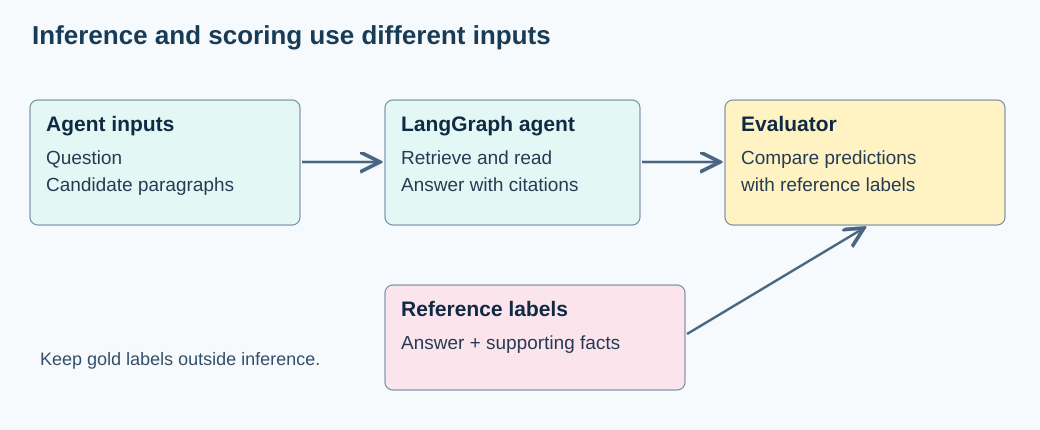

In [8]:
display(SVG(filename=str(ROOT / "assets" / "evaluation.svg")))

## 7. Preserve sentence addresses while retrieving paragraphs

We keep each candidate paragraph as one retrievable document. The text supplied to the model includes the title and every original sentence number. No re-splitting or renumbering occurs.

Our baseline uses **TF-IDF**: represent text by word weights, giving distinctive words more influence than common ones. Cosine similarity ranks paragraph vectors against the query vector. These are **sparse lexical vectors**, not neural embeddings. This choice keeps the first experiment local and inspectable. Dense embeddings and hybrid search are later extensions; HotpotQA does not require a particular retrieval method.

`k` is the maximum number of paragraphs returned **per search round**. Across rounds we accumulate the union of retrieved paragraphs, so a two-round run can expose up to `2 × k` distinct paragraphs, capped by the candidate count.

In [9]:
index = make_index(toy["context"])
print(inspect.getsource(make_index))
print(inspect.getsource(type(index).search))

def make_index(context: list) -> ParagraphIndex:
    """Accept only a record's context, never the whole labeled record."""
    documents = []
    for title, sentences in context:
        if not isinstance(title, str) or not isinstance(sentences, (list, tuple)):
            raise TypeError("Context entries must be [title, list_of_sentences]")
        if not all(isinstance(sentence, str) for sentence in sentences):
            raise TypeError("Every original sentence must be a string")
        documents.append(Paragraph(title, tuple(sentences)))
    return ParagraphIndex(documents)

    def search(self, query: str, k: int = 2) -> list[Paragraph]:
        """Cosine similarity: TF-IDF vectors are L2-normalized by default."""
        if k < 1:
            raise ValueError("k must be positive")
        scores = (self.matrix @ self.vectorizer.transform([query]).T).toarray().ravel()
        order = sorted(range(len(scores)), key=lambda i: (-float(scores[i]), i))
        return [self.documents[

In [10]:
first_hits = index.search(toy["question"], k=1)
print("First retrieved title:", first_hits[0].title)
print("Original sentences:", first_hits[0].sentences)

First retrieved title: Lantern Atlas
Original sentences: ('Lantern Atlas is an invented book whose creator is Mira Vale.',)


## 8. Build the agent with LangGraph

LangGraph represents work as a **state graph**. State carries the original question, current search query, retrieved evidence, decisions and trace. A node performs one step; an edge determines what happens next.

We adapt the [official agentic RAG tutorial](https://docs.langchain.com/oss/python/langgraph/agentic-rag): retrieve evidence, grade it, rewrite a query when needed, and generate an answer. Our adaptation always retrieves, keeps the original question separate from rewritten queries, accumulates evidence, and limits retrieval to two rounds. The official example also allows an initial model decision about whether to call a retrieval tool; that extra decision is unnecessary for this controlled evaluation.

**Routing:** after grading, sufficient evidence goes to generation. Insufficient evidence goes to rewrite if another round remains. When the round budget is exhausted, generation receives the limited evidence and may abstain. The stop condition does not certify that the evidence is sufficient.

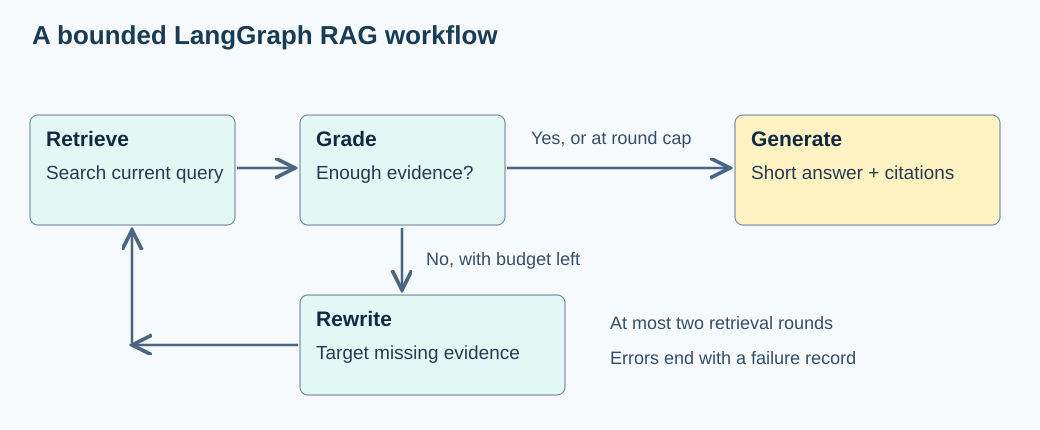

In [11]:
display(SVG(filename=str(ROOT / "assets" / "graph.svg")))

The implementation lives in the readable [rag.py](rag.py) module so tests and notebook runs use the same code. The next cell shows the actual graph construction. Read the nested functions in this order:

1. `retrieve` searches the current query and adds newly found paragraphs to the state. It increments the retrieval-round count.
2. `grade` asks whether the accumulated evidence covers the original question. The model's decision updates `sufficient`.
3. `rewrite` requests a query targeting missing evidence and updates only `query`, keeping `question` unchanged.
4. `generate` requests a short answer and exact sentence citations.
5. The routing functions send errors to the end, sufficient evidence to generation, and insufficient evidence to another search only while budget remains.
6. `StateGraph` registers nodes and edges, then `compile()` makes the runnable graph.

The helper catches backend failures and records the failed stage. Pay attention to the conditional edge and budget check. You can modify this function in the module, then restart the notebook kernel to load your changes.

In [12]:
print(inspect.getsource(build_graph))

def build_graph(index: ParagraphIndex, backend: Backend, max_rounds: int = 2, k: int = 2) -> RAGAgent:
    """Build a bounded agent; only retrieved text reaches the backend.

    With two retrieval rounds, at most four backend calls occur: grade, rewrite,
    grade, generate. At the cap we attempt a grounded answer even if the grade is
    negative; the generator is instructed to abstain if evidence is insufficient.
    """
    if type(max_rounds) is not int or not 1 <= max_rounds <= 2:
        raise ValueError("This tutorial allows one or two retrieval rounds")
    if type(k) is not int or k < 1:
        raise ValueError("k must be a positive integer")

    def record_node(name, function, *, model_call=False):
        def run(state):
            started = perf_counter()
            update = {}
            if model_call:
                update["backend_calls"] = state["backend_calls"] + 1
            try:
                update.update(function(state))
                event = {"node": n

## 9. Run a scripted graph walkthrough

A **scripted backend** supplies predetermined decisions and a predetermined answer. It is a test fixture, not a trained question-answering system. Here it makes the first grader decision false, rewrites the query to the bridge entity, then says the evidence is sufficient. This exposes the loop without requiring an API key.

We deliberately write the answer ourselves. A high score for this walkthrough proves only that graph execution, citation mapping and scoring are connected. It says nothing about a model's ability to solve unseen HotpotQA questions.

In [13]:
fixture = ScriptedBackend(
    grades=[False, True],
    rewrites=["Mira Vale birthplace"],
    answer=Answer(answer="Harbor City", citations=[
        Citation(title="Lantern Atlas", sentence_id=0),
        Citation(title="Mira Vale", sentence_id=0),
    ]),
)
demo_agent = build_graph(index, fixture, k=1, max_rounds=2)
demo = demo_agent.invoke(toy["question"])
print(json.dumps(demo, indent=2))
assert demo["retrieved_titles"] == ["Lantern Atlas", "Mira Vale"]
assert demo["status"] == "ok" and not demo["invalid_citations"]

{
  "answer": "Harbor City",
  "sp": [
    [
      "Lantern Atlas",
      0
    ],
    [
      "Mira Vale",
      0
    ]
  ],
  "retrieved_titles": [
    "Lantern Atlas",
    "Mira Vale"
  ],
  "retrieved_facts": [
    [
      "Lantern Atlas",
      0
    ],
    [
      "Mira Vale",
      0
    ]
  ],
  "invalid_citations": [],
  "status": "ok",
  "error": null,
  "rounds": 2,
  "backend_calls": 4,
  "latency_seconds": 0.002389541012234986,
  "trace": [
    {
      "node": "retrieve",
      "status": "ok",
      "query": "In which city was the creator of Lantern Atlas born?",
      "round": 1,
      "retrieved_titles": [
        "Lantern Atlas"
      ],
      "accumulated_titles": [
        "Lantern Atlas"
      ],
      "seconds": 0.0003244580002501607
    },
    {
      "node": "grade",
      "status": "ok",
      "sufficient": false,
      "reason": "Scripted teaching fixture decision",
      "seconds": 1.2208009138703346e-05
    },
    {
      "node": "rewrite",
      "status": "o

Read the trace in order. The first search should retrieve the book paragraph; the rewritten search should retrieve the creator paragraph. The accumulated evidence lets the reader see both. `backend_calls` counts grader, rewrite and answer calls, including attempted calls that fail. In this fixture they are local Python calls.

The wrapper validates citations against the evidence actually retrieved. It flags a made-up title or out-of-range sentence, and retains the claimed citation for scoring instead of silently changing it into a correct one. A valid address only establishes that a sentence exists in the evidence; it does not establish that the sentence supports the answer.

In [14]:
print("Graph structure (text, no external rendering service):")
print(demo_agent.graph.get_graph().draw_mermaid())
print("Retrieval coverage:", retrieval_metrics(demo["retrieved_facts"], toy))
print("Scripted fixture scores:", score_example(demo["answer"], demo["sp"], toy))

Graph structure (text, no external rendering service):
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	retrieve(retrieve)
	grade(grade)
	rewrite(rewrite)
	generate(generate)
	__end__([<p>__end__</p>]):::last
	__start__ --> retrieve;
	grade -.-> __end__;
	grade -.-> generate;
	grade -.-> rewrite;
	retrieve -.-> __end__;
	retrieve -.-> grade;
	rewrite -.-> __end__;
	rewrite -.-> retrieve;
	generate --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

Retrieval coverage: {'support_fact_recall': 1.0, 'support_title_recall': 1.0, 'all_support_titles': 1.0}
Scripted fixture scores: {'em': 1.0, 'f1': 1.0, 'prec': 1.0, 'recall': 1.0, 'sp_em': 1.0, 'sp_f1': 1.0, 'sp_prec': 1.0, 'sp_recall': 1.0, 'joint_em': 1.0, 'joint_f1': 1.0, 'joint_prec': 1.0, 'joint_recall': 1.0}


## 10. Calculate answer exact match and token F1

The official normalizer lowercases, removes ASCII punctuation, removes the English articles `a`, `an`, `the`, and normalizes whitespace. **Exact match (EM)** is 1 if the normalized strings match and 0 otherwise.

For token F1, count shared tokens with multiplicity. Precision is the share of predicted tokens that match; recall is the share of reference tokens recovered. F1 is their harmonic mean, `2 × precision × recall / (precision + recall)`, with zero when there is no overlap.

Example: reference `Harbor City`, prediction `Harbor`. One of one predicted tokens matches, but only one of two reference tokens is recovered. Precision = 1, recall = 1/2, F1 = 2/3, EM = 0. These are text-overlap measures, not semantic judges: extra explanation or a valid alias can lose points.

In [15]:
answer_examples = [
    ("The Harbor City!", "Harbor City"),
    ("Harbor", "Harbor City"),
    ("Harbor Harbor", "Harbor City"),
    ("yes indeed", "yes"),
    ("", "Harbor City"),
]
display(pd.DataFrame([
    {"prediction": p, "reference": g, **answer_metrics(p, g)}
    for p, g in answer_examples
]))

,prediction,reference,em,f1,prec,recall
0,The Harbor City!,Harbor City,1.0,1.000000,1.0,1.0
1,Harbor,Harbor City,0.0,0.666667,1.0,0.5
2,Harbor Harbor,Harbor City,0.0,0.500000,0.5,0.5
3,yes indeed,yes,0.0,0.000000,0.0,0.0
4,,Harbor City,0.0,0.000000,0.0,0.0


The special answers `yes`, `no` and `noanswer` receive zero token precision, recall and F1 if either normalized string is special and the two strings differ. Thus `yes indeed` is not partial credit for `yes`. This is official scorer behavior. The live reader uses an empty answer and no citations for abstention. `noanswer` is an official scoring special case; neither it nor an empty answer is correct for an ordinary answerable record.

## 11. Score the selected supporting facts

Supporting facts use **sets of exact pairs**. Order and duplicate citations do not matter. Titles remain case-sensitive; answer-text normalization does not apply to them.

Suppose gold has two pairs. Predict one correct pair and one unrelated pair. There is one true positive, one false positive and one false negative: precision = 1/2, recall = 1/2, F1 = 1/2, EM = 0. Predicting every sentence may increase recall but adds false positives and lowers precision.

Retrieving an entire paragraph makes its sentences *available*. Citing a subset chooses which sentences the answer *claims as evidence*. These operations answer different evaluation questions.

In [16]:
gold_sp = toy["supporting_facts"]
wrong_sp = [["Lantern Atlas", 0], ["Harbor City", 0]]
print("One correct + one wrong:", supporting_fact_metrics(wrong_sp, gold_sp))
print("Correct pairs duplicated:", supporting_fact_metrics(gold_sp + gold_sp, gold_sp))
print("Correct retrieval, poor citation selection can coexist:")
print(retrieval_metrics(demo["retrieved_facts"], toy))
print(supporting_fact_metrics(wrong_sp, gold_sp))

One correct + one wrong: {'em': 0.0, 'f1': 0.5, 'prec': 0.5, 'recall': 0.5}
Correct pairs duplicated: {'em': 1.0, 'f1': 1.0, 'prec': 1.0, 'recall': 1.0}
Correct retrieval, poor citation selection can coexist:
{'support_fact_recall': 1.0, 'support_title_recall': 1.0, 'all_support_titles': 1.0}
{'em': 0.0, 'f1': 0.5, 'prec': 0.5, 'recall': 0.5}


## 12. Calculate the joint score correctly

For each question, the official evaluator combines **precision with precision** and **recall with recall**:

- `joint_precision = answer_precision × supporting_fact_precision`
- `joint_recall = answer_recall × supporting_fact_recall`
- `joint_F1 = harmonic_mean(joint_precision, joint_recall)`
- `joint_EM = answer_EM × supporting_fact_EM`

It then averages each metric over questions. **Joint F1 is generally not the product of answer F1 and supporting-fact F1.**

Worked example: answer `Harbor` gives answer precision 1 and recall 1/2. Citing both correct pairs plus one wrong pair gives supporting-fact precision 2/3 and recall 1. Joint precision is 2/3 and joint recall is 1/2, so joint F1 is 4/7 ≈ 0.5714. Multiplying the component F1s would give `(2/3) × (4/5) ≈ 0.5333`, a different result.

In [17]:
joint_case = score_example("Harbor", gold_sp + [["Harbor City", 0]], toy)
display(pd.Series(joint_case, name="worked example"))
assert abs(joint_case["joint_f1"] - 4/7) < 1e-12
print("Incorrect F1 product:", joint_case["f1"] * joint_case["sp_f1"])

em              0.000000
f1              0.666667
prec            1.000000
recall          0.500000
sp_em           0.000000
sp_f1           0.800000
sp_prec         0.666667
sp_recall       1.000000
joint_em        0.000000
joint_f1        0.571429
joint_prec      0.666667
joint_recall    0.500000
Name: worked example, dtype: float64

Incorrect F1 product: 0.5333333333333333


## 13. Export the official prediction format

The outer JSON contains two objects named `answer` and `sp`. Each maps a question ID to a short answer or list of supporting-fact pairs. Traces, runtime and model metadata go in separate files. Do not rename `sp` to `supporting_facts` in predictions: that longer name belongs to the gold data schema.

The fixture below deliberately copies known labels to test the **scorer**, not the agent. Missing predictions still contribute a zero for the missing metric to the whole-dataset average. Never drop failed requests from the denominator.

In [18]:
fixture_predictions = {
    "answer": {toy["_id"]: "Harbor City"},
    "sp": {toy["_id"]: [["Lantern Atlas", 0], ["Mira Vale", 0]]},
}
print(json.dumps(fixture_predictions, indent=2))
print("Scorer sanity check only:", evaluate(fixture_predictions, [toy]))
print("Missing output:", evaluate({"answer": {}, "sp": {}}, [toy]))

{
  "answer": {
    "synthetic-lantern-atlas-001": "Harbor City"
  },
  "sp": {
    "synthetic-lantern-atlas-001": [
      [
        "Lantern Atlas",
        0
      ],
      [
        "Mira Vale",
        0
      ]
    ]
  }
}
Scorer sanity check only: {'em': 1.0, 'f1': 1.0, 'prec': 1.0, 'recall': 1.0, 'sp_em': 1.0, 'sp_f1': 1.0, 'sp_prec': 1.0, 'sp_recall': 1.0, 'joint_em': 1.0, 'joint_f1': 1.0, 'joint_prec': 1.0, 'joint_recall': 1.0}
Missing output: {'em': 0.0, 'f1': 0.0, 'prec': 0.0, 'recall': 0.0, 'sp_em': 0.0, 'sp_f1': 0.0, 'sp_prec': 0.0, 'sp_recall': 0.0, 'joint_em': 0.0, 'joint_f1': 0.0, 'joint_prec': 0.0, 'joint_recall': 0.0}


## 14. Measure retrieval on actual records

Now use the real bundled questions. We compare the same records at `k = 1, 2, 4, 10` without a generator. This isolates retrieval. A paragraph's sentences keep their original indices, so we can compare their addresses with the gold facts after searching.

**Supporting-title recall** is the fraction of annotated titles found. **All-support-titles** is 1 only if every annotated title was retrieved. **Supporting-fact recall** is the fraction of gold sentence addresses available to the reader. With intact paragraphs these coverage measures are closely related. They are custom diagnostics, not additional official HotpotQA leaderboard metrics.

At `k=10`, all candidate paragraphs should be available on a standard distractor record, giving complete coverage. This is a useful sanity check but does not demonstrate useful ranking or correct answers.

In [19]:
retrieval_rows = []
for record in records:
    local_index = make_index(record["context"])
    for k in [1, 2, 4, 10]:
        hits = local_index.search(record["question"], k=k)
        available = [(doc.title, i) for doc in hits for i in range(len(doc.sentences))]
        retrieval_rows.append({"_id": record["_id"], "type": record["type"], "k": k,
                               **retrieval_metrics(available, record)})
retrieval_df = pd.DataFrame(retrieval_rows)
coverage_columns = ["support_title_recall", "all_support_titles", "support_fact_recall"]
display(retrieval_df.groupby("k")[coverage_columns].mean().round(3))
display(retrieval_df.groupby(["type", "k"])[coverage_columns].mean().round(3))
assert (retrieval_df.query("k == 10")["support_fact_recall"] == 1).all()

,support_title_recall,all_support_titles,support_fact_recall
k,,,
1,0.30,0.0,0.290
2,0.50,0.2,0.473
4,0.65,0.4,0.623
10,1.00,1.0,1.000


support_title_recall  all_support_titles  support_fact_recall
type       k                                                                
bridge     1                    0.3                 0.0                0.280
           2                    0.6                 0.2                0.547
           4                    0.7                 0.4                0.647
           10                   1.0                 1.0                1.000
comparison 1                    0.3                 0.0                0.300
           2                    0.4                 0.2                0.400
           4                    0.6                 0.4                0.600
           10                   1.0                 1.0                1.000

The table reports fractions between 0 and 1. Multiplying by 100 converts them to percentages. A larger `k` spends more context on the reader and may include more distracting text. Retrieval coverage alone cannot tell us which value gives the best end-to-end answer score.

**Try this:** find a record that misses at least one supporting title at `k=2`. Look at the question words and the selected paragraphs. Does the missing paragraph require a bridge entity that does not occur in the original question? Do not tune on these records and then report them as unseen test data.

In [20]:
misses = retrieval_df.query("k == 2 and all_support_titles < 1")
if len(misses):
    miss_id = misses.iloc[0]["_id"]
    miss = next(r for r in records if r["_id"] == miss_id)
    print("Question:", miss["question"])
    print("Retrieved:", [d.title for d in make_index(miss["context"]).search(miss["question"], k=2)])
    print("Annotated support titles:", sorted({t for t, _ in miss["supporting_facts"]}))
else:
    print("No k=2 title miss in this tiny sample; that is not evidence of general reliability.")

Question: Were Scott Derrickson and Ed Wood of the same nationality?
Retrieved: ['Woodson, Arkansas', 'Ed Wood (film)']
Annotated support titles: ['Ed Wood', 'Scott Derrickson']


## 15. Replace the fixture with a live model

The same graph accepts `LiveBackend`, which asks a model to return structured grader decisions, rewritten queries and answers with citations. Schema validation checks the response shape; it does not verify truth. All model prompts see the question and retrieved text only. The reference labels stay in the harness.

Copy `.env.example` to `.env` in this directory and set `OPENAI_API_KEY` plus `OPENAI_MODEL` to a model your account supports. It must support the structured output interface used by LangChain. Keep keys out of notebook cells and outputs. This setup loads only this module's `.env`, with existing environment variables taking precedence.

Set `RUN_LIVE = True` in section 1 only when ready. The default runs two real questions, at most two search rounds each. Each question uses at most two grading calls, one rewrite and one generation call: **four model calls**, at most eight for the default batch. Client retries are disabled, each call has a timeout and output-token cap. Input size and token prices still determine cost; this is a work bound, not a fixed price quote.

A model/API error remains an error result in the batch and contributes to the denominator. There is no automatic substitution of a scripted answer.

In [21]:
if RUN_LIVE:
    from dotenv import load_dotenv
    from langchain_openai import ChatOpenAI
    load_dotenv(ROOT / ".env")
    model_name = os.environ.get("OPENAI_MODEL", "").strip()
    if not os.environ.get("OPENAI_API_KEY") or not model_name:
        raise ValueError("Set OPENAI_API_KEY and OPENAI_MODEL in the module .env or environment.")
    llm = ChatOpenAI(model=model_name, max_retries=0, timeout=45, max_tokens=1200)
    selected = records[:LIVE_N]
    if not 1 <= LIVE_N <= len(records):
        raise ValueError("LIVE_N must be between 1 and the bundled sample size.")
    live_result = run_experiment(selected, lambda: LiveBackend(llm), k=K, max_rounds=MAX_ROUNDS)
    display(pd.DataFrame(live_result["rows"]))
    display(pd.Series(live_result["metrics"], name="live run, small teaching subset"))
else:
    print("Skipped: live model. Offline examples above use explicitly scripted answers.")

Skipped: live model. Offline examples above use explicitly scripted answers.


## 16. Inspect failures before comparing systems

A score locates a problem; a trace helps explain it. Use this sequence on each low-scoring result:

| Observation | Plausible explanation to investigate |
|---|---|
| Low support coverage | Retrieval missed a required paragraph; query rewrite may help |
| Full coverage, wrong answer | Reader confusion, bad comparison, or insufficient useful context |
| Correct answer, weak supporting-fact score | Incomplete, irrelevant or incorrect citation selection; possible memorization |
| Valid citation addresses, wrong evidence | Address validation passed, but the cited text does not support the claim |
| Error status | Provider, parsing or configuration failure; inspect the error and attempted calls |

These are hypotheses, not proven causes. Run a **gold-evidence diagnostic** separately if useful: give a reader just the annotated evidence to isolate reading difficulty. Label it explicitly as an oracle condition and never mix it into normal retrieval results. Likewise, a no-context model condition helps probe memorization but cannot prove its absence.

In [22]:
if RUN_LIVE:
    live_df = pd.DataFrame(live_result["rows"])
    print("Error rate:", (live_df["status"] == "failed").mean())
    print("Mean model calls:", live_df["backend_calls"].mean())
    print("Median latency (seconds):", live_df["latency_seconds"].median())
    display(live_df.groupby("type")[["em", "f1", "sp_f1", "joint_f1"]].agg(["count", "mean"]))
    worst = live_df.sort_values("joint_f1").iloc[0]["_id"]
    print(json.dumps(next(r for r in live_result["runs"] if r["_id"] == worst), indent=2))
else:
    print("Failure inspection will run after a live experiment.")

Failure inspection will run after a live experiment.


## 17. Save predictions and run the official evaluator

A saved experiment includes its exact question IDs, data hash, package versions, configuration, predictions, traces and metrics. Each run uses a new directory so rerunning the notebook does not overwrite earlier evidence. The helper also saves the matching gold subset: scoring a two-question prediction file against the full development set would count all other questions as missing.

The bundled upstream script is pinned and attributed. The command below invokes it directly on your saved files. Our tests also compare the tutorial metrics against the upstream implementation, including special answers, duplicate citations and missing predictions.

In [23]:
if RUN_LIVE:
    from datetime import datetime, timezone
    run_name = datetime.now(timezone.utc).strftime("live-%Y%m%dT%H%M%S%fZ")
    output_dir = save_experiment(live_result, selected, ROOT / "artifacts" / run_name,
                                 model=model_name, k=K, max_rounds=MAX_ROUNDS,
                                 client_settings={"timeout_seconds": 45, "max_retries": 0, "max_tokens": 1200})
    print("Saved:", output_dir)
    import subprocess
    official = ROOT / "data" / "upstream" / "hotpot_evaluate_v1.py"
    completed = subprocess.run([sys.executable, str(official),
                                str(output_dir / "predictions.json"), str(output_dir / "gold.json")],
                               text=True, capture_output=True, check=True)
    print("Official evaluator:", completed.stdout)
else:
    print("No live prediction files written. Enable the live section to export a real model run.")

No live prediction files written. Enable the live section to export a real model run.


## 18. Design a fair comparison

Choose one change at a time: `k`, one versus two retrieval rounds, the retrieval method, or the model. Run both configurations on **the same frozen question IDs**, keep prompts and all other settings fixed, and retain every attempted request. Report the paired per-question score differences as well as the means.

For a larger study, sample IDs reproducibly before inspecting labels. Freeze a development/tuning split and a held-out evaluation split. Use adequate counts for bridge and comparison analyses. Confidence intervals from a paired bootstrap resample question IDs and recompute the mean difference; they describe sampling uncertainty, not model contamination or dataset coverage. Repeat hosted runs when stochastic output matters. Temperature or seed settings do not guarantee provider-level determinism.

A result report should state: dataset release and split, exact candidate corpus, sample size and selection, IDs/hash, retrieval settings, model identifier, prompts/code version, error policy, answer/SP/joint metrics, coverage, latency and calls. Avoid comparing a tiny distractor subset directly to fullwiki leaderboard scores.

In [24]:
# A paired retrieval comparison; these are coverage differences, not answer gains.
paired = retrieval_df.pivot(index="_id", columns="k", values="all_support_titles")
paired["difference_k4_minus_k2"] = paired[4] - paired[2]
display(paired[[2, 4, "difference_k4_minus_k2"]])
print("Mean paired coverage difference:", paired["difference_k4_minus_k2"].mean())

k,2,4,difference_k4_minus_k2
_id,,,
5a85b2d95542997b5ce40028,0.0,1.0,1.0
5a85ea095542994775f606a8,0.0,0.0,0.0
5a8b57f25542995d1e6f1371,0.0,0.0,0.0
5a8c7595554299585d9e36b6,0.0,0.0,0.0
5a8db19d5542994ba4e3dd00,0.0,0.0,0.0
5a8e3ea95542995a26add48d,0.0,0.0,0.0
5ab29c24554299449642c932,0.0,1.0,1.0
5ab56e32554299637185c594,0.0,0.0,0.0
5abd94525542992ac4f382d2,1.0,1.0,0.0


Mean paired coverage difference: 0.2


## 19. Exercises and limits

1. Change one citation to sentence index `99`. Predict which score changes and whether citation validation accepts it. **Expected:** the address is invalid, a false positive replaces useful evidence, and supporting-fact/joint scores fall.
2. Keep the answer correct but remove one supporting fact. **Expected:** answer EM stays 1 while supporting-fact recall and joint F1 fall.
3. Force the scripted grader to reject evidence twice. **Expected:** the graph stops after the configured round budget. Stopping does not make the evidence sufficient.
4. Compare `k=2` and `k=4` with a live reader on fresh held-out IDs. **Expected:** greater retrieval coverage need not improve answering; inspect evidence and cost before drawing a conclusion.
5. Replace TF-IDF with dense or hybrid retrieval while keeping titles and original sentence indices. **Expected:** changes in ranking can now be measured without changing the scorer.

HotpotQA labels are annotations, not an exhaustive list of every semantically valid explanation. Exact supporting-fact scoring can penalize plausible alternative evidence. Answer F1 can penalize aliases and reward partial lexical overlap. Dataset contamination can produce a correct answer without useful retrieval. A full product evaluation also needs domain-specific tasks, human-reviewed failure cases, safety requirements and production constraints.

You now have a concrete evaluation pipeline to extend: raw records, traceable retrieval, a real LangGraph workflow, independently scored predictions and reproducible exports.

## 20. References and attribution

- Yang et al. (2018), [HotpotQA: A Dataset for Diverse, Explainable Multi-hop Question Answering](https://aclanthology.org/D18-1259/).
- [HotpotQA project, downloads and settings](https://hotpotqa.github.io/).
- [HotpotQA repository and evaluation script](https://github.com/hotpotqa/hotpot).
- LangChain, [Build a custom RAG agent with LangGraph](https://docs.langchain.com/oss/python/langgraph/agentic-rag). Our workflow is an adaptation explained in section 8.
- scikit-learn, [text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction).

See [SOURCES.md](SOURCES.md) and [data/README.md](data/README.md) for exact provenance, pinned upstream code and licensing. See [VALIDATION.md](VALIDATION.md) for execution and review evidence, including the boundary between offline verification and unrun hosted calls.